# Pattabiraman EMT figure reproduction

This notebook reproduces the four plots in `SE_Pattibaraman.ipynb` from the packaged per-cell values. It does not load AnnData or rerun the ortholog/network pipeline.

Input: `source_data/Input_Pattabiraman_percell.csv`. Figures and pairwise statistics are written to `figures/` and `source_data/`.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

SOURCE = Path('source_data')
FIGURES = Path('figures')
SOURCE.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
mpl.rcParams.update({'figure.dpi':150,'savefig.dpi':600,'savefig.bbox':'tight','pdf.fonttype':42,'ps.fonttype':42})
sns.set_theme(style='white', context='paper')

SAMPLE_ORDER = ['E','EM1','EM2','EM3','M']
cells = pd.read_csv(SOURCE / 'Input_Pattabiraman_percell.csv', index_col='cell_id')

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png')
    fig.savefig(FIGURES / f'{name}.pdf')

def groups(column):
    return [cells.loc[cells['Sample'] == stage, column].dropna().to_numpy() for stage in SAMPLE_ORDER]

def welch_matrix(column, name):
    rows=[]
    for first, second in combinations(SAMPLE_ORDER, 2):
        x=cells.loc[cells.Sample == first, column].dropna(); y=cells.loc[cells.Sample == second, column].dropna()
        statistic, pvalue=ttest_ind(x, y, equal_var=False)
        rows.append({'Group1':first,'Group2':second,'n1':len(x),'n2':len(y),'t_stat':statistic,'p_value':pvalue})
    result=pd.DataFrame(rows); result['p_adj']=multipletests(result['p_value'],method='fdr_bh')[1]
    matrix=pd.DataFrame(np.nan,index=SAMPLE_ORDER,columns=SAMPLE_ORDER)
    for _, row in result.iterrows(): matrix.loc[row.Group1,row.Group2]=row.p_adj; matrix.loc[row.Group2,row.Group1]=row.p_adj
    result.to_csv(SOURCE / f'{name}_pairwise.csv', index=False); matrix.to_csv(SOURCE / f'{name}_pairwise_matrix.csv')
    return matrix

print(f'{len(cells):,} cells; missing values: {int(cells.isna().sum().sum())}')

13,924 cells; missing values: 0


## CCAT across EMT stages

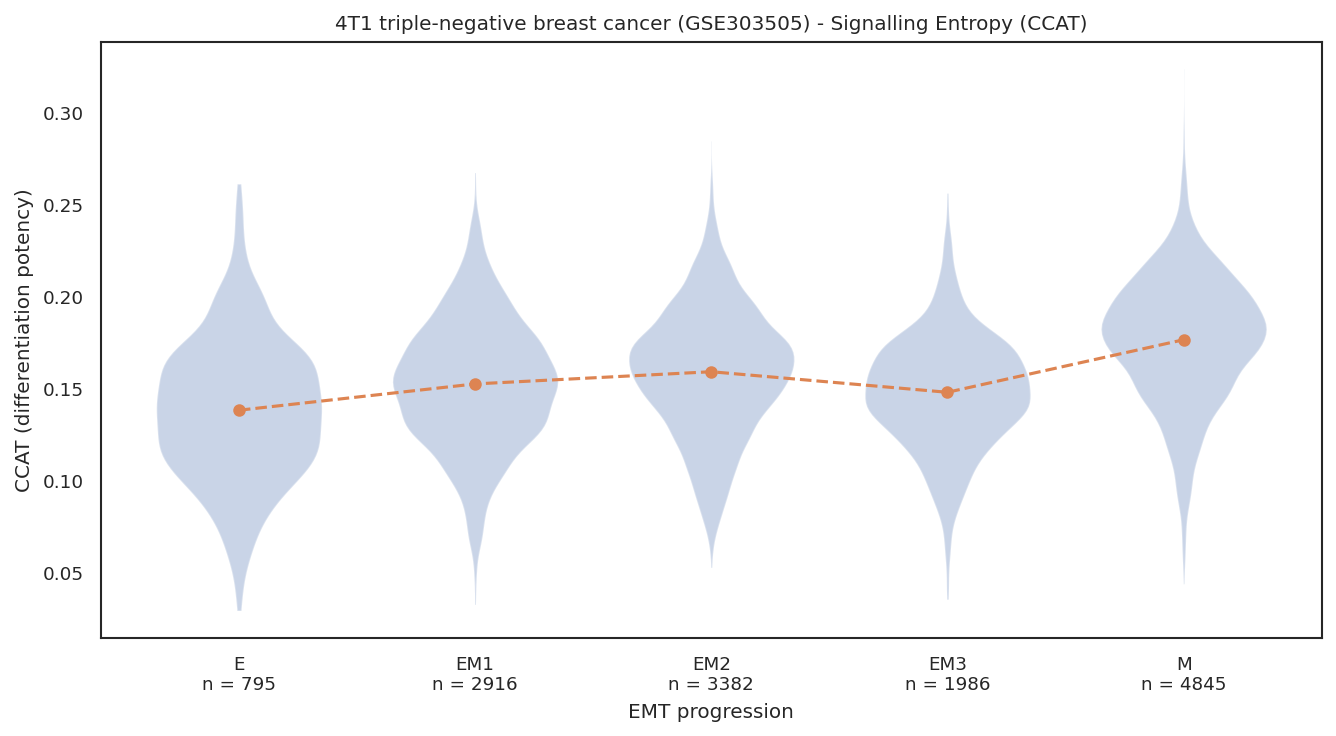

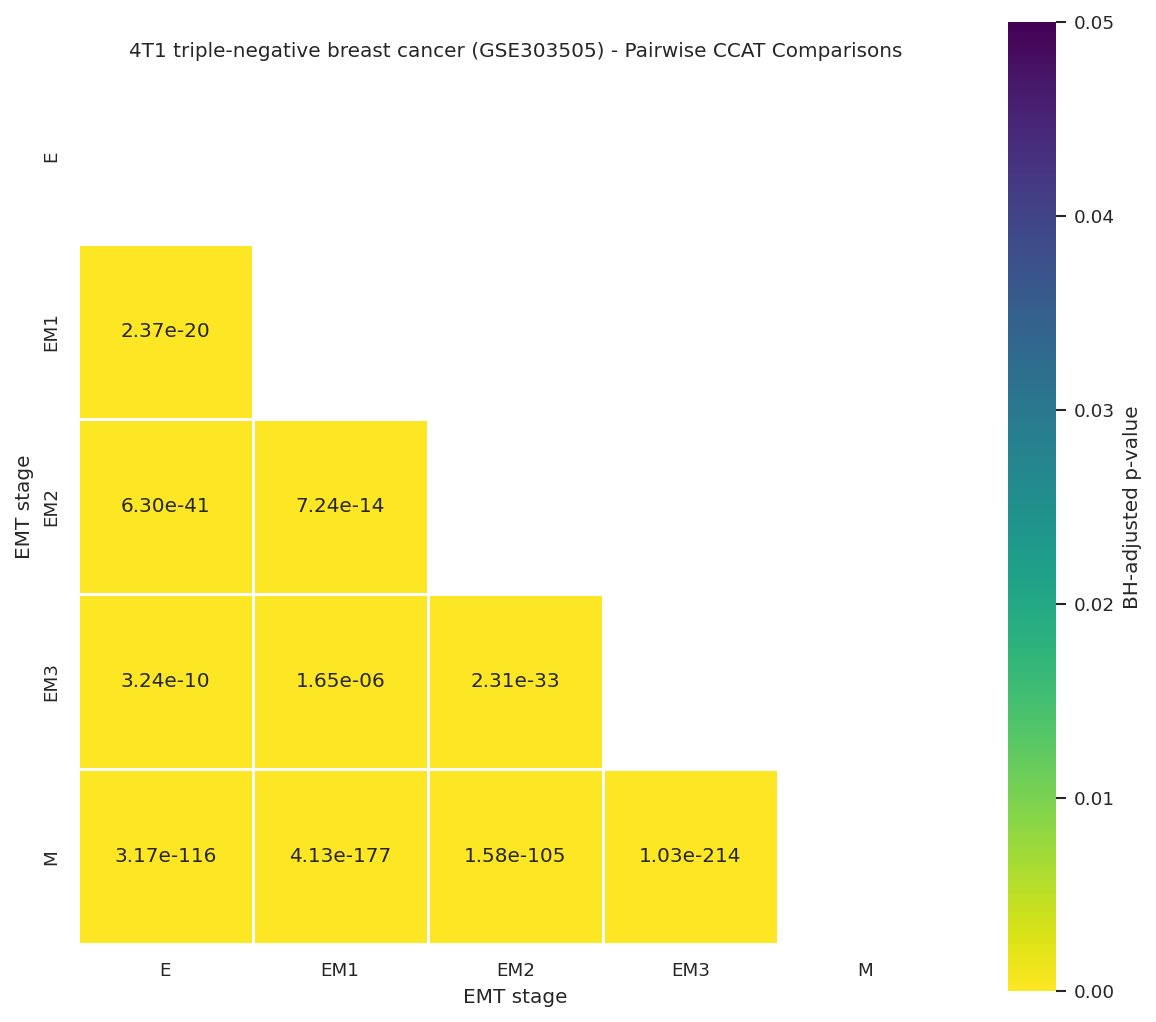

In [3]:
x=np.arange(len(SAMPLE_ORDER)); data=groups('CCAT'); means=[values.mean() for values in data]; counts=cells['Sample'].value_counts().reindex(SAMPLE_ORDER)
fig, ax=plt.subplots(figsize=(9,5)); ax.violinplot(data,positions=x,widths=0.7,showmeans=False,showmedians=False,showextrema=False); ax.plot(x,means,'o--',linewidth=1.5,markersize=5)
ax.set_xticks(x); ax.set_xticklabels([f'{stage}\nn = {int(counts.loc[stage])}' for stage in SAMPLE_ORDER]); ax.set_xlabel('EMT progression'); ax.set_ylabel('CCAT (differentiation potency)'); ax.set_title('4T1 triple-negative breast cancer (GSE303505) - Signalling Entropy (CCAT)'); fig.tight_layout(); save_figure(fig,'panel01_ccat_across_emt'); plt.show()

ccat_matrix=welch_matrix('CCAT','Pattabiraman_ccat')
fig, ax=plt.subplots(figsize=(8,7)); sns.heatmap(ccat_matrix,mask=np.triu(np.ones_like(ccat_matrix,dtype=bool)),annot=True,fmt='.2e',cmap='viridis_r',vmin=0,vmax=0.05,linewidths=0.5,square=True,cbar_kws={'label':'BH-adjusted p-value'},ax=ax); ax.set_title('4T1 triple-negative breast cancer (GSE303505) - Pairwise CCAT Comparisons'); ax.set_xlabel('EMT stage'); ax.set_ylabel('EMT stage'); fig.tight_layout(); save_figure(fig,'panel02_ccat_pairwise'); plt.show()

## Shannon entropy across EMT stages

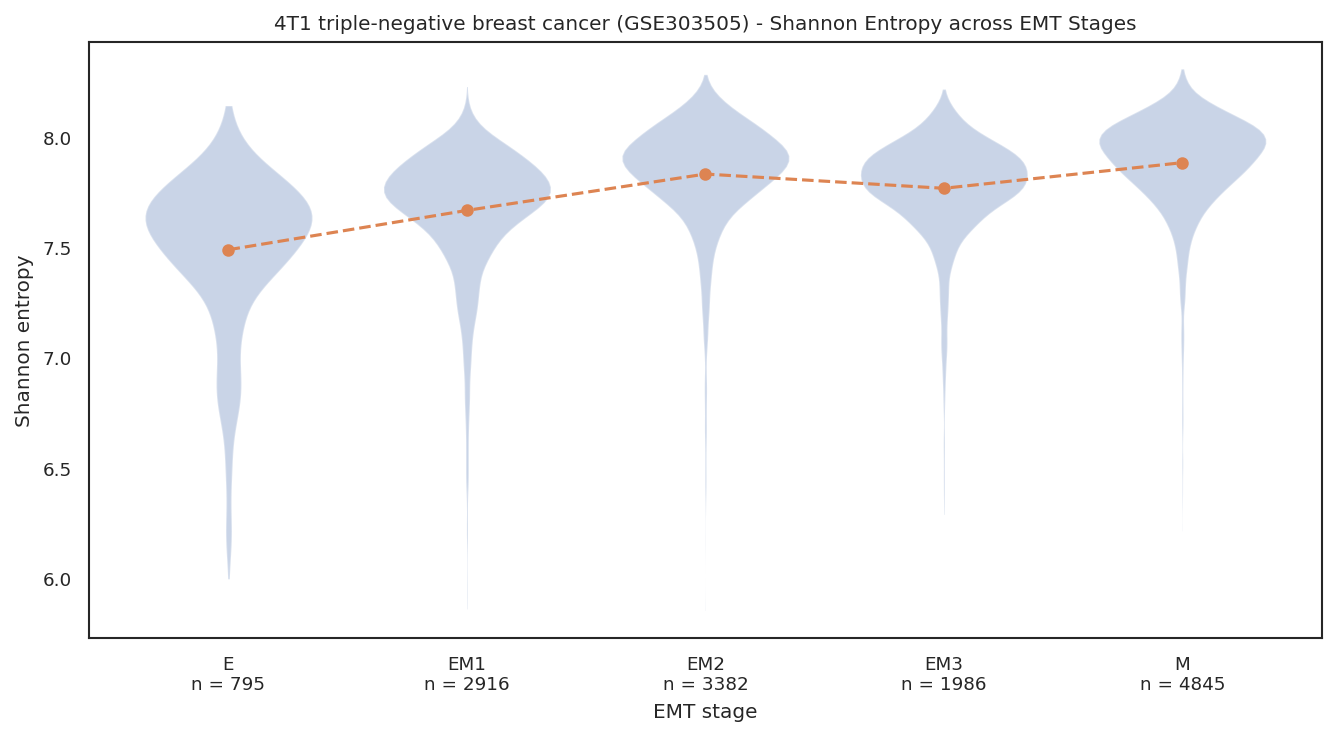

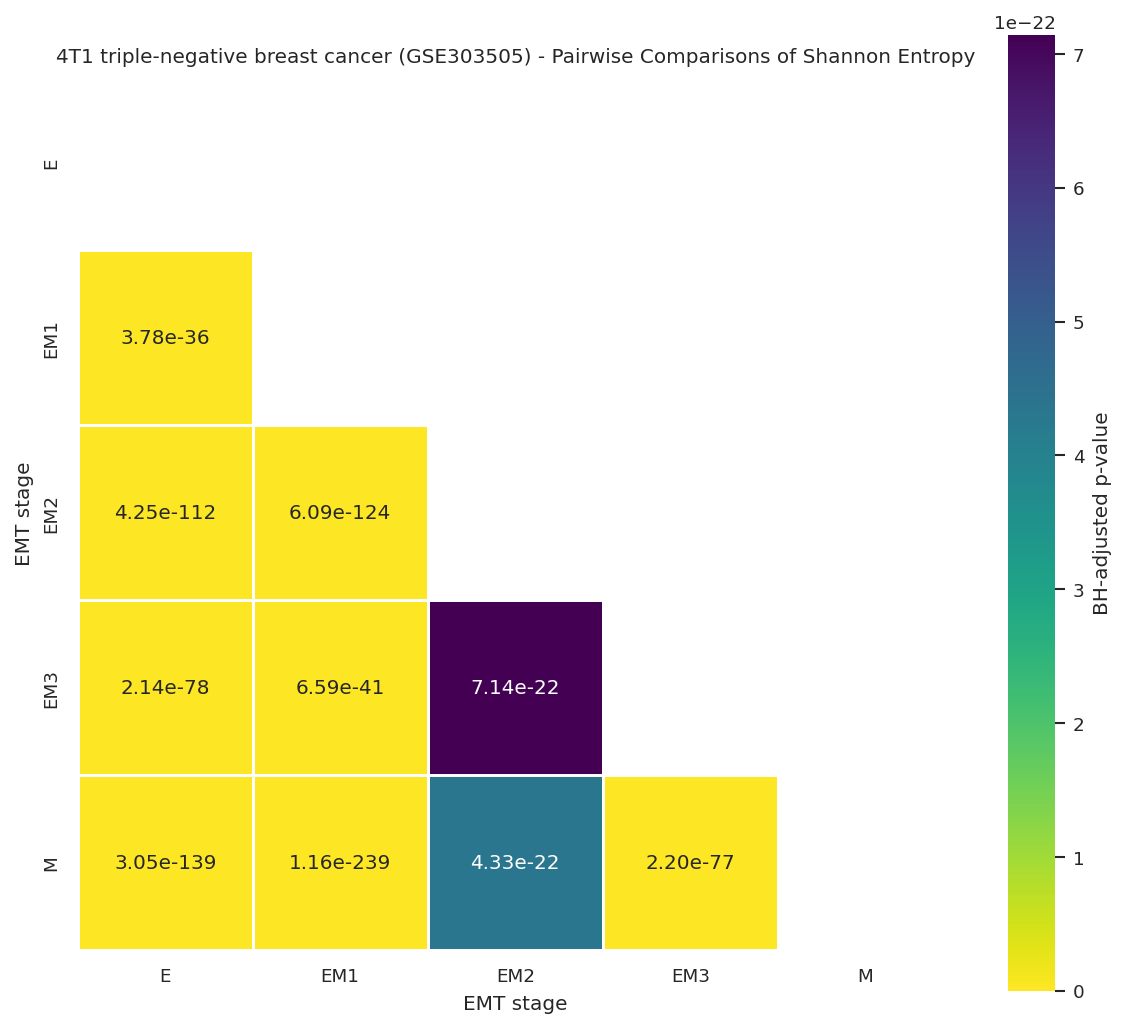

In [4]:
data=groups('Shannon_entropy'); means=[values.mean() for values in data]; counts=cells['Sample'].value_counts().reindex(SAMPLE_ORDER)
fig, ax=plt.subplots(figsize=(9,5)); ax.violinplot(data,positions=x,widths=0.7,showmeans=False,showmedians=False,showextrema=False); ax.plot(x,means,'o--',linewidth=1.5,markersize=5); ax.set_xticks(x); ax.set_xticklabels([f'{stage}\nn = {int(counts.loc[stage])}' for stage in SAMPLE_ORDER]); ax.set_xlabel('EMT stage'); ax.set_ylabel('Shannon entropy'); ax.set_title('4T1 triple-negative breast cancer (GSE303505) - Shannon Entropy across EMT Stages'); fig.tight_layout(); save_figure(fig,'panel03_shannon_entropy_across_emt'); plt.show()

entropy_matrix=welch_matrix('Shannon_entropy','Pattabiraman_shannon_entropy')
fig, ax=plt.subplots(figsize=(8,7)); sns.heatmap(entropy_matrix,mask=np.triu(np.ones_like(entropy_matrix,dtype=bool)),annot=True,fmt='.2e',cmap='viridis_r',linewidths=0.5,square=True,cbar_kws={'label':'BH-adjusted p-value'},ax=ax); ax.set_title('4T1 triple-negative breast cancer (GSE303505) - Pairwise Comparisons of Shannon Entropy'); ax.set_xlabel('EMT stage'); ax.set_ylabel('EMT stage'); fig.tight_layout(); save_figure(fig,'panel04_shannon_entropy_pairwise'); plt.show()